# Bài thực hành 3: Naive Bayes

**Sinh viên:** Nguyễn Thành Phong · **Học phần:** Học máy ứng dụng · **Giảng viên:** ThS. Nguyễn Thái Anh

Dữ liệu:
- `data/tin_nhan.csv`: 300 tin nhắn, 2 cột `noi_dung` (chữ) và `la_rac` (1 = rác, 0 = thường).
- `data/sinh_vien.csv`: dùng lại từ bài 2, 120 sinh viên, 3 cột `gio_on`, `diem_giua_ky`, `qua_mon`.

Mỗi mục bên dưới ứng với một tệp trong `code/` (phần bài giảng) hoặc `baitap03/` (phần bài tập).
Chạy các tệp đó từ thư mục `Lab03/`, ví dụ `python baitap03/bai1.py`.

In [1]:
# Chuẩn bị dữ liệu: chạy local thì đọc thẳng, trên Colab thì tải hai tệp lên
import os
CAN_CO = ["data/tin_nhan.csv", "data/sinh_vien.csv"]
if not all(os.path.exists(p) for p in CAN_CO):
    from google.colab import files
    files.upload()                         # chon ca tin_nhan.csv va sinh_vien.csv
    os.makedirs("data", exist_ok=True)
    for p in CAN_CO:
        if os.path.exists(os.path.basename(p)):
            os.replace(os.path.basename(p), p)
for p in CAN_CO:
    print(f"Co {p} chua?", os.path.exists(p))

Co data/tin_nhan.csv chua? True
Co data/sinh_vien.csv chua? True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB

# Hai màu cố định cho hai lớp, dùng chung cho mọi hình
MAU_THUONG = "#2a78d6"     # tin thường / qua môn
MAU_RAC = "#eb6834"        # tin rác / rớt môn
MAU_CHU = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MAU_CHU, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "lines.linewidth": 2,
})

## 1. Định lý Bayes (`code/d1_bayes_tay.py`)

$$\mathbb{P}(A \mid B) = \frac{\mathbb{P}(B \mid A)\,\mathbb{P}(A)}{\mathbb{P}(B)}$$

In [3]:
def bayes(tien_nghiem, kha_nang, kha_nang_nguoc):
    """Tra ve xac suat hau nghiem.

    tien_nghiem    : P(A), niem tin truoc khi co bang chung
    kha_nang       : P(B | A), bang chung xuat hien khi A dung
    kha_nang_nguoc : P(B | khong A), bang chung xuat hien khi A sai
    """
    tu_so = kha_nang * tien_nghiem
    mau_so = tu_so + kha_nang_nguoc * (1 - tien_nghiem)
    return tu_so / mau_so


print("Vi du 1: xet nghiem benh")
print("  Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.")
p = bayes(tien_nghiem=0.01, kha_nang=0.99, kha_nang_nguoc=0.01)
print(f"  Duong tinh thi kha nang co benh that = {p:.4f}")
print()

# Giữ nguyên chất lượng xét nghiệm, chỉ đổi tỷ lệ mắc bệnh
print("Cung xet nghiem do, doi ty le mac benh:")
print("  Ty le mac benh    Hau nghiem khi duong tinh")
for ty_le in [0.001, 0.01, 0.05, 0.10, 0.50]:
    print(f"    {ty_le:6.3f}             {bayes(ty_le, 0.99, 0.01):.4f}")
print()

print("Vi du 2: hai day chuyen san xuat")
print("  Day A lam 80 phan tram san pham, ty le loi 1 phan tram.")
print("  Day B lam 20 phan tram san pham, ty le loi 5 phan tram.")
# Ở đây "A đúng" nghĩa là sản phẩm đến từ dây B
p_b = bayes(tien_nghiem=0.20, kha_nang=0.05, kha_nang_nguoc=0.01)
print(f"  Nhat duoc san pham loi, kha nang no tu day B = {p_b:.4f}")
print()

print("Kiem lai bang cach dem tren 1000 san pham:")
loi_a = 800 * 0.01
loi_b = 200 * 0.05
print(f"  Day A: 800 san pham, {loi_a:.0f} cai loi")
print(f"  Day B: 200 san pham, {loi_b:.0f} cai loi")
tong_loi = loi_a + loi_b
print(f"  Ty le tu day B = {loi_b} / {tong_loi} = {loi_b / tong_loi:.4f}")

Vi du 1: xet nghiem benh
  Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.
  Duong tinh thi kha nang co benh that = 0.5000

Cung xet nghiem do, doi ty le mac benh:
  Ty le mac benh    Hau nghiem khi duong tinh
     0.001             0.0902
     0.010             0.5000
     0.050             0.8390
     0.100             0.9167
     0.500             0.9900

Vi du 2: hai day chuyen san xuat
  Day A lam 80 phan tram san pham, ty le loi 1 phan tram.
  Day B lam 20 phan tram san pham, ty le loi 5 phan tram.
  Nhat duoc san pham loi, kha nang no tu day B = 0.5556

Kiem lai bang cach dem tren 1000 san pham:
  Day A: 800 san pham, 8 cai loi
  Day B: 200 san pham, 10 cai loi
  Ty le tu day B = 10.0 / 18.0 = 0.5556


**Nhận xét.** Kết quả khớp tài liệu: xét nghiệm dương tính thì khả năng có bệnh thật chỉ là 0.5000, và nhặt được sản phẩm lỗi thì khả năng nó đến từ dây B là 0.5556.

Bảng giữa là phần đáng chú ý nhất. Chất lượng xét nghiệm giữ nguyên, chỉ tỷ lệ mắc bệnh thay đổi, mà hậu nghiệm chạy từ 0.0902 (bệnh hiếm 0.1%) lên 0.9900 (bệnh phổ biến 50%). Tiên nghiệm quan trọng ngang với bằng chứng. Ví dụ dây chuyền cho thấy cùng ý đó theo chiều ngược lại: dây B chỉ làm 20% sản phẩm nhưng tỷ lệ lỗi gấp 5 lần dây A, nên vẫn chiếm 10 trong 18 sản phẩm lỗi.

## 2. Biến văn bản thành số (`code/d2_tui_tu.py`)

In [4]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

df = pd.read_csv("data/tin_nhan.csv")

print("Kich thuoc bang:", df.shape)
print()
print("So tin theo nhan (1 la rac, 0 la thuong):")
print(df["la_rac"].value_counts())
print()
print("Ty le tin rac:", round(df["la_rac"].mean(), 4))
print()

print("Ba tin nhan dau tien:")
for i in range(3):
    print(f"  [{df.la_rac[i]}] {df.noi_dung[i]}")
print()

# token_pattern mặc định của scikit-learn bỏ mất từ một ký tự,
# nên ta chỉ định tách từ bằng khoảng trắng cho đơn giản.
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])

print("Kich thuoc bang dem tu:", X.shape)
print("So tu trong tu dien:", len(vec.vocabulary_))
print()

# Đếm tổng số lần xuất hiện của từng từ, tách theo hai lớp
dem = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())
dem["la_rac"] = df["la_rac"]
tong = dem.groupby("la_rac").sum().T
tong.columns = ["thuong", "rac"]

print("Muoi tu xuat hien nhieu nhat trong tin rac:")
print(tong.sort_values("rac", ascending=False).head(10))
print()
print("Muoi tu xuat hien nhieu nhat trong tin thuong:")
print(tong.sort_values("thuong", ascending=False).head(10))

Kich thuoc bang: (300, 2)

So tin theo nhan (1 la rac, 0 la thuong):
la_rac
0    180
1    120
Name: count, dtype: int64

Ty le tin rac: 0.4

Ba tin nhan dau tien:
  [0] cáo gửi cáo thầy nhóm cáo gửi có cho
  [1] miễn giảm ngay hạn miễn tay nhé thưởng cho nhanh
  [0] cho bạn mai gửi nhóm bài chiều

Kich thuoc bang dem tu: (300, 40)
So tu trong tu dien: 40

Muoi tu xuat hien nhieu nhat trong tin rac:
       thuong  rac
tay         3   48
ngay        4   47
nhanh       9   44
chót        6   43
giảm        6   42
lúc        39   42
quà         8   41
phí         6   40
click       5   40
tặng        7   39

Muoi tu xuat hien nhieu nhat trong tin thuong:
       thuong  rac
thầy       74    7
bài        73    4
cáo        72    8
chiều      68    8
ạ          65    7
tài        64   11
tập        63    6
gửi        61   10
lớp        60    2
nhóm       58    7


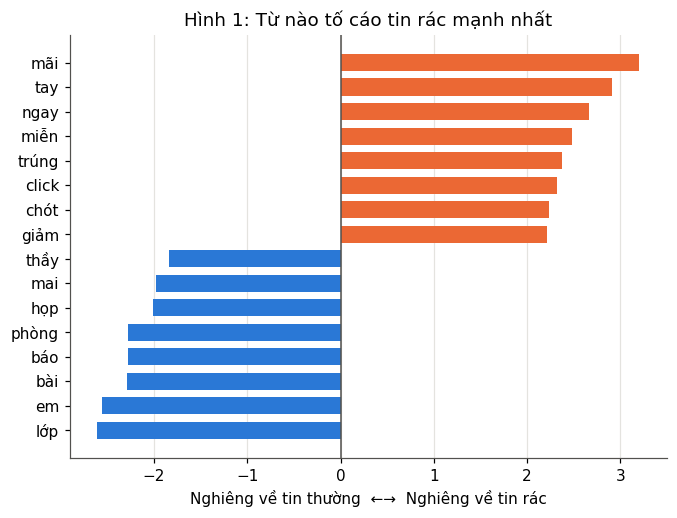

In [5]:
# Hình 1: mức chênh lệch giữa hai lớp của từng từ (huấn luyện trên cả 300 tin)
nb_toan_bo = MultinomialNB().fit(X, df["la_rac"])
chenh = nb_toan_bo.feature_log_prob_[1] - nb_toan_bo.feature_log_prob_[0]
tu = vec.get_feature_names_out()
thu_tu = np.argsort(chenh)
chon = np.r_[thu_tu[:8], thu_tu[-8:]]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(tu[chon], chenh[chon], height=0.7,
        color=[MAU_RAC if v > 0 else MAU_THUONG for v in chenh[chon]])
ax.axvline(0, color=MAU_CHU, lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Nghiêng về tin thường  ←→  Nghiêng về tin rác")
ax.set_title("Hình 1: Từ nào tố cáo tin rác mạnh nhất")
plt.show()

**Nhận xét.** Bảng đếm có kích thước 300 × 40, tức mỗi tin nhắn thành một dãy 40 con số. Các từ `tay` (48 lần ở tin rác, 3 lần ở tin thường), `ngay` (47 / 4), `click` (40 / 5) gần như chỉ có trong tin rác. Ngược lại `thầy` (7 / 74), `bài` (4 / 73), `lớp` (2 / 60) gần như chỉ có trong tin thường. Từ `lúc` xuất hiện nhiều ở cả hai lớp (42 / 39) nên không giúp phân loại.

Hình 1 vẽ hiệu loga xác suất của từng từ giữa hai lớp: `mãi`, `tay`, `ngay` đứng đầu phía rác, `lớp`, `em`, `bài` đứng đầu phía thường (bài tập 2 in đúng các con số này).

Hạng 10 của bảng tin rác là chỗ hòa: `tặng` và `miễn` cùng xuất hiện 39 lần, nên từ in ra ở hạng đó có thể khác tài liệu tùy cách pandas sắp xếp.

## 3. Bộ lọc tin nhắn rác (`code/d3_loc_thu_rac.py`)

$$\hat y = \arg\max_k \; \mathbb{P}(y = k) \prod_{j=1}^{d} \mathbb{P}(x_j \mid y = k)$$

In [6]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv("data/tin_nhan.csv")
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])
y = df["la_rac"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print("So tin de hoc     :", X_train.shape[0])
print("So tin de kiem tra:", X_test.shape[0])
print()

mo_hinh = MultinomialNB(alpha=1.0)
mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma tran nham lan")
print(f"  TN = {tn:2d}   thu thuong duoc giu dung")
print(f"  FP = {fp:2d}   thu thuong bi xoa nham")
print(f"  FN = {fn:2d}   thu rac lot luoi")
print(f"  TP = {tp:2d}   thu rac bi chan dung")
print()

print(f"Accuracy  = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall    = {recall_score(y_test, y_pred):.4f}")
print()

# Thử bộ lọc trên vài tin nhắn tự gõ
tin_moi = [
    "trung thuong khuyen mai nhanh tay click ngay",
    "hop nhom bao cao chieu mai phong 305",
    "ban gui giup em tai lieu bai tap nhe",
]
X_moi = vec.transform(tin_moi)
p_rac = mo_hinh.predict_proba(X_moi)[:, 1]

print("Thu tren ba tin nhan tu go:")
for tin, p in zip(tin_moi, p_rac):
    nhan = "RAC" if p >= 0.5 else "thuong"
    print(f"  [{nhan:6s}] p = {p:.4f}  <- {tin}")

So tin de hoc     : 225
So tin de kiem tra: 75

Ma tran nham lan
  TN = 45   thu thuong duoc giu dung
  FP =  0   thu thuong bi xoa nham
  FN =  4   thu rac lot luoi
  TP = 26   thu rac bi chan dung

Accuracy  = 0.9467
Precision = 1.0000
Recall    = 0.8667

Thu tren ba tin nhan tu go:
  [RAC   ] p = 0.9992  <- trung thuong khuyen mai nhanh tay click ngay
  [thuong] p = 0.0983  <- hop nhom bao cao chieu mai phong 305
  [thuong] p = 0.0719  <- ban gui giup em tai lieu bai tap nhe


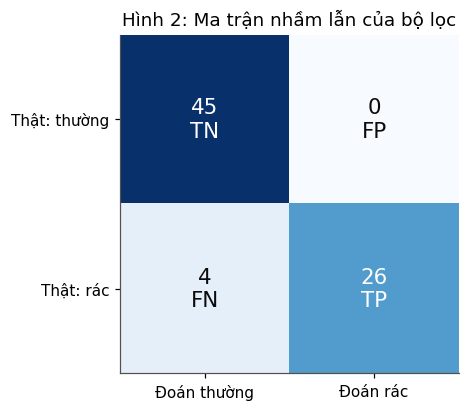

In [7]:
# Hình 2: ma trận nhầm lẫn trên 75 tin kiểm tra
cm = confusion_matrix(y_test, y_pred)
nhan_o = [["TN", "FP"], ["FN", "TP"]]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n{nhan_o[i][j]}", ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
ax.set_xticks([0, 1], ["Đoán thường", "Đoán rác"])
ax.set_yticks([0, 1], ["Thật: thường", "Thật: rác"])
ax.set_title("Hình 2: Ma trận nhầm lẫn của bộ lọc")
plt.show()

**Nhận xét.** Kết quả khớp bảng 8 của tài liệu: TN = 45, FP = 0, FN = 4, TP = 26; accuracy 0.9467, precision 1.0000, recall 0.8667 (Hình 2).

Với bộ lọc thư rác, FP (xóa nhầm thư thật) đắt hơn nhiều so với FN (để lọt tin rác), nên FP = 0 có giá trị hơn con số accuracy. Bốn tin rác lọt lưới là những tin viết gần như toàn từ của tin thường, ví dụ `gửi nhanh cáo chiều họp liệu phòng này có ạ`. Mô hình gán cho cả bốn tin xác suất rác gần 0. Túi từ không thể bắt được loại tin này.

Về ba tin tự gõ: chúng viết **không dấu**, còn từ điển là tiếng Việt có dấu. CountVectorizer chỉ nhận ra `mai, nhanh, tay, click, ngay` ở tin thứ nhất, chỉ `mai` ở tin thứ hai và chỉ `em` ở tin thứ ba. Vậy hai con số 0.0983 và 0.0719 dựa trên đúng một từ mỗi tin. Đây chính là giới hạn mà tài liệu nêu ở mục 5.4: từ ngoài từ điển bị bỏ qua hoàn toàn, làm trơn cũng không cứu được.

## 4. Vấn đề số không và làm trơn Laplace (`code/d4_lam_tron.py`)

$$\mathbb{P}(\text{từ } j \mid \text{lớp } k) = \frac{\text{đếm}_{jk} + \alpha}{\text{tổng}_k + \alpha V}$$

In [8]:
from collections import Counter

# Kho tin nhắn tí hon, viết thẳng vào mã cho dễ theo dõi
kho = [
    ("trung thuong ngay", 1),
    ("khuyen mai giam gia", 1),
    ("trung thuong click", 1),
    ("hop nhom chieu mai", 0),
    ("bai tap nhom nop mai", 0),
    ("thay gui tai lieu", 0),
]

tu_dien = sorted({t for cau, _ in kho for t in cau.split()})
V = len(tu_dien)
print(f"Tu dien co {V} tu:")
# In thành nhiều dòng, mỗi dòng 9 từ, để không tràn ra ngoài khung
for i in range(0, V, 9):
    print("  " + " ".join(tu_dien[i:i + 9]))
print()

# Đếm số lần mỗi từ xuất hiện trong từng lớp
dem = {0: Counter(), 1: Counter()}
tong = {0: 0, 1: 0}
for cau, nhan in kho:
    for t in cau.split():
        dem[nhan][t] += 1
        tong[nhan] += 1

print("So lan xuat hien cua tung tu")
print(f"  {'tu':12s} {'rac':>5s} {'thuong':>7s}")
for t in tu_dien:
    print(f"  {t:12s} {dem[1][t]:5d} {dem[0][t]:7d}")
print()


def xac_suat(tu, nhan, alpha):
    """P(tu | nhan) co lam tron Laplace voi he so alpha."""
    return (dem[nhan][tu] + alpha) / (tong[nhan] + alpha * V)


def diem(cau, nhan, alpha):
    """Tich cua xac suat tien nghiem va cac xac suat tu."""
    p = 0.5           # hai lop can bang nen tien nghiem bang nhau
    for t in cau.split():
        if t in tu_dien:
            p *= xac_suat(t, nhan, alpha)
    return p


cau_thu = "trung thuong bai tap"
print(f"Tin nhan thu: \"{cau_thu}\"")
print("Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.")
print()

for alpha in [0.0, 1.0]:
    d_rac = diem(cau_thu, 1, alpha)
    d_thuong = diem(cau_thu, 0, alpha)
    ket = "rac" if d_rac > d_thuong else "thuong"
    print(f"alpha = {alpha}")
    print(f"  diem lop rac    = {d_rac:.10f}")
    print(f"  diem lop thuong = {d_thuong:.10f}")
    print(f"  ket luan        = {ket}")
    print()

print("Khong lam tron, CA HAI diem deu bang 0 nen mo hinh te liet.")
print("Lop rac bang 0 vi tu 'bai' chua tung xuat hien o lop rac.")
print("Lop thuong bang 0 vi tu 'trung' chua tung xuat hien o lop thuong.")
print("Co lam tron, diem lop rac lon hon va mo hinh ket luan dung.")

Tu dien co 18 tu:
  bai chieu click gia giam gui hop khuyen lieu
  mai ngay nhom nop tai tap thay thuong trung

So lan xuat hien cua tung tu
  tu             rac  thuong
  bai              0       1
  chieu            0       1
  click            1       0
  gia              1       0
  giam             1       0
  gui              0       1
  hop              0       1
  khuyen           1       0
  lieu             0       1
  mai              1       2
  ngay             1       0
  nhom             0       2
  nop              0       1
  tai              0       1
  tap              0       1
  thay             0       1
  thuong           2       0
  trung            2       0

Tin nhan thu: "trung thuong bai tap"
Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.

alpha = 0.0
  diem lop rac    = 0.0000000000
  diem lop thuong = 0.0000000000
  ket luan        = thuong

alpha = 1.0
  diem lop rac    = 0.0000073212
  diem lop thuong = 0.0000021656
  ket luan        = rac


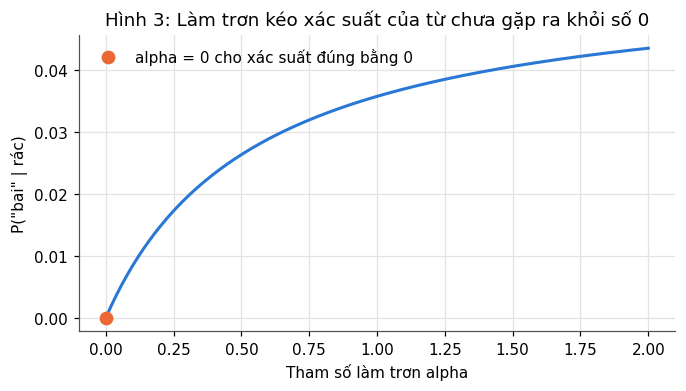

In [9]:
# Hình 3: xác suất của từ 'bai' (chưa từng gặp ở lớp rác) theo alpha, trên kho tí hon
cac_alpha = np.linspace(0, 2, 201)
p_bai = [xac_suat("bai", 1, a) for a in cac_alpha]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cac_alpha, p_bai, color=MAU_THUONG)
ax.plot([0], [0], "o", color=MAU_RAC, ms=8, label="alpha = 0 cho xác suất đúng bằng 0")
ax.set_xlabel("Tham số làm trơn alpha"); ax.set_ylabel('P("bai" | rác)')
ax.set_title("Hình 3: Làm trơn kéo xác suất của từ chưa gặp ra khỏi số 0")
ax.legend(frameon=False); plt.show()

**Nhận xét.** Khi α = 0, cả hai điểm đều bằng 0. Lớp rác bằng 0 vì từ `bai` chưa từng xuất hiện ở lớp rác, lớp thường bằng 0 vì `trung` chưa từng xuất hiện ở lớp thường. Phép so sánh `0 > 0` sai nên mã rơi về nhánh `else` và in ra "thuong": kết luận đó do cách viết mã quyết định chứ mô hình không hề suy luận.

Khi α = 1, điểm lớp rác 0.0000073212 lớn gấp khoảng 3.4 lần lớp thường 0.0000021656, nên mô hình kết luận đúng là tin rác. Hình 3 vẽ P(`bai` | rác) = α / (9 + 18α) trên kho tí hon: đúng bằng 0 tại α = 0 và tăng dần khi α tăng.

## 5. Naive Bayes cho số liệu liên tục (`code/d5_gaussian.py`)

In [10]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai mô hình, cùng dữ liệu, cùng cách chia, nên so sánh mới công bằng
for ten, mo_hinh in [("Naive Bayes     ", GaussianNB()),
                     ("Hoi quy logistic", LogisticRegression())]:
    mo_hinh.fit(X_train, y_train)
    acc = accuracy_score(y_test, mo_hinh.predict(X_test))
    print(f"{ten}: accuracy = {acc:.4f}")
print()

gnb = GaussianNB().fit(X_train, y_train)

# theta_ la trung binh, var_ la phuong sai, moi dong mot lop
print("Nhung gi Naive Bayes hoc duoc")
print(f"  {'':16s} {'gio_on':>10s} {'diem_giua_ky':>14s}")
for i, ten_lop in enumerate(["Lop 0 (rot) ", "Lop 1 (qua) "]):
    tb = gnb.theta_[i]
    dl = gnb.var_[i] ** 0.5
    print(f"  {ten_lop} trung binh {tb[0]:10.2f} {tb[1]:14.2f}")
    print(f"  {'':12s} do lech    {dl[0]:10.2f} {dl[1]:14.2f}")
print()

ty_le = ", ".join(f"{float(v):.4f}" for v in gnb.class_prior_)
print(f"Ty le tung lop trong tap hoc: {ty_le}")
print()

# Dự đoán cho vài sinh viên giả định
ban_moi = pd.DataFrame({"gio_on": [5, 13, 20, 28],
                        "diem_giua_ky": [4.0, 6.0, 7.0, 9.0]})
p = gnb.predict_proba(ban_moi)[:, 1]
print("Du doan cho bon ban moi:")
print(f"  {'gio on':>8s} {'diem GK':>9s} {'P(qua mon)':>12s}")
for (_, r), pi in zip(ban_moi.iterrows(), p):
    print(f"  {r.gio_on:8.0f} {r.diem_giua_ky:9.1f} {pi:12.4f}")

Naive Bayes     : accuracy = 0.9000
Hoi quy logistic: accuracy = 0.9000

Nhung gi Naive Bayes hoc duoc
                       gio_on   diem_giua_ky
  Lop 0 (rot)  trung binh       8.18           3.99
               do lech          5.29           1.92
  Lop 1 (qua)  trung binh      20.03           6.70
               do lech          5.81           1.50

Ty le tung lop trong tap hoc: 0.4111, 0.5889

Du doan cho bon ban moi:
    gio on   diem GK   P(qua mon)
         5       4.0       0.0137
        13       6.0       0.6550
        20       7.0       0.9855
        28       9.0       0.9999


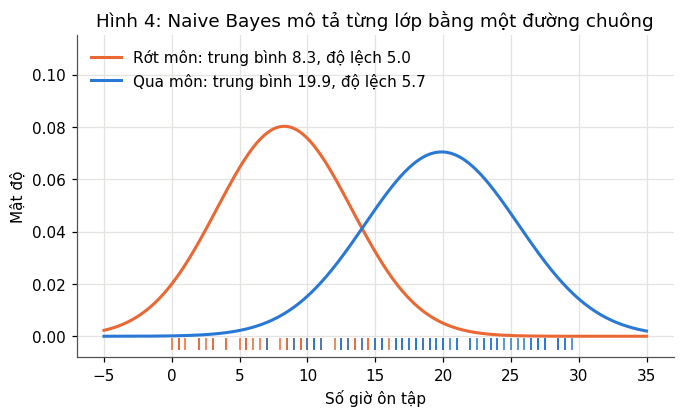

In [11]:
# Hình 4: mỗi lớp một đường chuông cho số giờ ôn (trên cả 120 sinh viên)
def mat_do_chuan(x, tb, dl):
    return np.exp(-0.5 * ((x - tb) / dl) ** 2) / (dl * np.sqrt(2 * np.pi))

xs = np.linspace(-5, 35, 400)
fig, ax = plt.subplots(figsize=(7, 3.8))
for nhan, mau, ten in [(0, MAU_RAC, "Rớt môn"), (1, MAU_THUONG, "Qua môn")]:
    gio = df.loc[df["qua_mon"] == nhan, "gio_on"]
    tb, dl = gio.mean(), gio.std()
    ax.plot(xs, mat_do_chuan(xs, tb, dl), color=mau, label=f"{ten}: trung bình {tb:.1f}, độ lệch {dl:.1f}")
    ax.plot(gio, np.full(len(gio), -0.003), "|", color=mau, ms=8)
ax.set_xlabel("Số giờ ôn tập"); ax.set_ylabel("Mật độ")
ax.set_ylim(-0.008, 0.115)
ax.set_title("Hình 4: Naive Bayes mô tả từng lớp bằng một đường chuông")
ax.legend(frameon=False, loc="upper left"); plt.show()

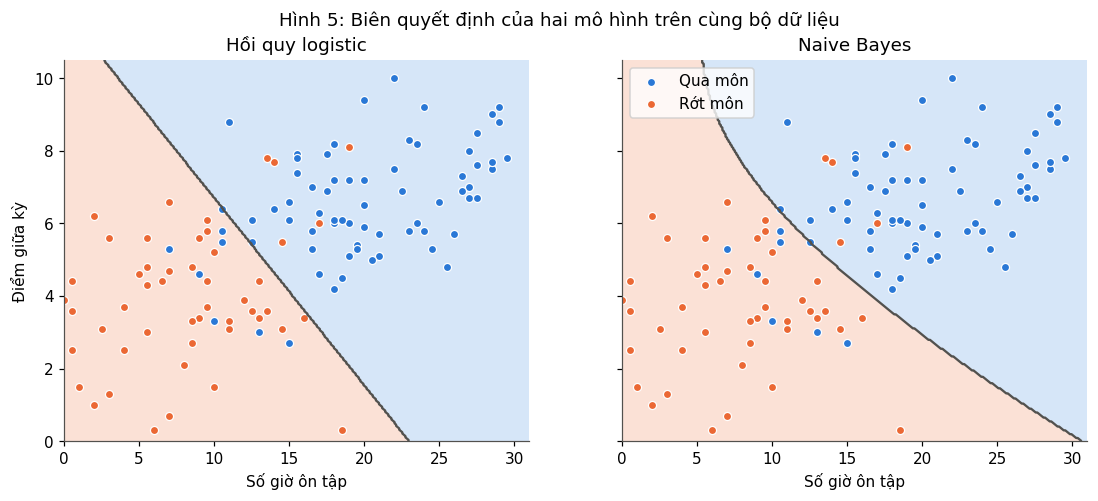

In [12]:
# Hình 5: biên quyết định của hai mô hình trên cùng tập học
gx, gy = np.meshgrid(np.linspace(0, 31, 300), np.linspace(0, 10.5, 300))
luoi = pd.DataFrame({"gio_on": gx.ravel(), "diem_giua_ky": gy.ravel()})
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (ten, m) in zip(axs, [("Hồi quy logistic", LogisticRegression()), ("Naive Bayes", GaussianNB())]):
    m.fit(X_train, y_train)
    vung = m.predict(luoi).reshape(gx.shape)
    ax.contourf(gx, gy, vung, levels=[-0.5, 0.5, 1.5], colors=["#fbe1d6", "#d6e6f8"])
    ax.contour(gx, gy, vung, levels=[0.5], colors=MAU_CHU, linewidths=1.5)
    for nhan, mau, ten_lop in [(1, MAU_THUONG, "Qua môn"), (0, MAU_RAC, "Rớt môn")]:
        nhom = df[df["qua_mon"] == nhan]
        ax.scatter(nhom["gio_on"], nhom["diem_giua_ky"], c=mau, s=28, edgecolor="white", linewidth=0.8, label=ten_lop)
    ax.set_title(ten); ax.set_xlabel("Số giờ ôn tập"); ax.grid(False)
axs[0].set_ylabel("Điểm giữa kỳ"); axs[1].legend(loc="upper left", frameon=True)
fig.suptitle("Hình 5: Biên quyết định của hai mô hình trên cùng bộ dữ liệu"); plt.show()

 So tin hoc   Naive Bayes   Hoi quy logistic
      10        0.9131         0.8712
      20        0.9349         0.9088
      30        0.9389         0.9157
      50        0.9437         0.9208
      80        0.9453         0.9237
     150        0.9467         0.9251
     225        0.9467         0.9200


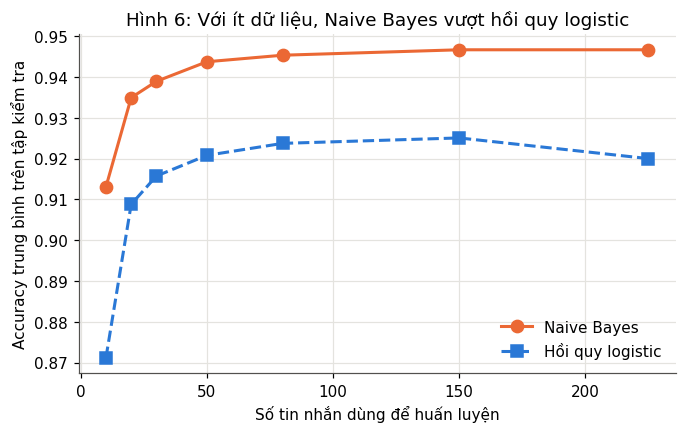

In [13]:
# Hình 6: accuracy trung bình theo số tin dùng để huấn luyện, trên bài lọc tin rác
df_tin = pd.read_csv("data/tin_nhan.csv")
vec_tin = CountVectorizer(token_pattern=r"(?u)\S+")
X_tin = vec_tin.fit_transform(df_tin["noi_dung"])
y_tin = df_tin["la_rac"]
Xh, Xk, yh, yk = train_test_split(X_tin, y_tin, test_size=0.25, random_state=17, stratify=y_tin)

co_mau = [10, 20, 30, 50, 80, 150, 225]
SO_LAN = 50                      # mỗi cỡ mẫu bốc ngẫu nhiên 50 lần rồi lấy trung bình
tb_nb, tb_lr = [], []
for n in co_mau:
    acc_nb, acc_lr = [], []
    for lan in range(SO_LAN if n < Xh.shape[0] else 1):
        if n < Xh.shape[0]:
            Xn, _, yn, _ = train_test_split(Xh, yh, train_size=n, random_state=lan, stratify=yh)
        else:
            Xn, yn = Xh, yh
        acc_nb.append(accuracy_score(yk, MultinomialNB().fit(Xn, yn).predict(Xk)))
        acc_lr.append(accuracy_score(yk, LogisticRegression(max_iter=1000).fit(Xn, yn).predict(Xk)))
    tb_nb.append(np.mean(acc_nb)); tb_lr.append(np.mean(acc_lr))

print(" So tin hoc   Naive Bayes   Hoi quy logistic")
for n, a, b in zip(co_mau, tb_nb, tb_lr):
    print(f"   {n:5d}        {a:.4f}         {b:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(co_mau, tb_nb, "o-", color=MAU_RAC, ms=8, label="Naive Bayes")
ax.plot(co_mau, tb_lr, "s--", color=MAU_THUONG, ms=8, label="Hồi quy logistic")
ax.set_xlabel("Số tin nhắn dùng để huấn luyện"); ax.set_ylabel("Accuracy trung bình trên tập kiểm tra")
ax.set_title("Hình 6: Với ít dữ liệu, Naive Bayes vượt hồi quy logistic")
ax.legend(frameon=False); plt.show()

**Nhận xét.** Hai mô hình cùng đạt accuracy 0.9000 trên 30 sinh viên kiểm tra. GaussianNB cho biết thêm hình dạng từng lớp: nhóm rớt ôn trung bình 8.18 giờ, điểm giữa kỳ 3.99; nhóm qua ôn 20.03 giờ, điểm giữa kỳ 6.70. Hồi quy logistic không trả lời được câu hỏi kiểu đó.

Hình 5: biên của hồi quy logistic là đường thẳng. Biên của Naive Bayes là đường cong, vì hai lớp có độ lệch chuẩn khác nhau nên biên giữa hai phân phối chuẩn là đường bậc hai. Trong vùng có dữ liệu hai biên gần trùng nhau, nên hai mô hình đoán gần như giống nhau.

Hình 6: ở mọi cỡ mẫu, Naive Bayes đều cao hơn hồi quy logistic. Khoảng cách rộng nhất khi chỉ có 10 tin huấn luyện (0.9131 so với 0.8712) và còn 0.9467 so với 0.9200 khi dùng đủ 225 tin; hai con số ở 225 tin khớp tài liệu. Ở 10 tin, khoảng cách ở đây nhỏ hơn tài liệu (0.9072 so với 0.7808) vì mỗi cỡ mẫu được bốc 50 tập con có giữ tỷ lệ lớp rồi lấy trung bình, trong khi tài liệu không nêu cách bốc mẫu. Kết luận không đổi: khi dữ liệu ít, Naive Bayes trụ vững hơn.

---
# Bài tập

Mã của từng bài nằm trong `baitap03/baiN.py`; ô bên dưới chạy đúng mã đó.

## Bài tập 1: Bayes với ba nguyên nhân
Ba nhóm sinh viên: 50% học đều, 30% học dồn, 20% ít học; tỷ lệ qua môn lần lượt 0.95, 0.70, 0.30. Gặp một bạn đã qua môn, tính xác suất bạn đó thuộc từng nhóm.

In [14]:
def bayes_nhieu_nhanh(tien_nghiem, kha_nang):
    """Tra ve (danh sach hau nghiem, P(B)).

    tien_nghiem : [P(A1), P(A2), ...], cac nhanh roi nhau, cong lai bang 1
    kha_nang    : [P(B | A1), P(B | A2), ...]
    """
    tu_so = [p * l for p, l in zip(tien_nghiem, kha_nang)]
    mau_so = sum(tu_so)               # P(B), xac suat toan phan
    return [t / mau_so for t in tu_so], mau_so


ten_nhom = ["hoc deu", "hoc don", "it hoc"]
ty_le_nhom = [0.50, 0.30, 0.20]       # tiên nghiệm P(nhóm)
ty_le_qua = [0.95, 0.70, 0.30]        # khả năng P(qua | nhóm)

hau_nghiem, p_qua = bayes_nhieu_nhanh(ty_le_nhom, ty_le_qua)

print("Ba nhom sinh vien")
print(f"  {'nhom':10s} {'P(nhom)':>8s} {'P(qua | nhom)':>14s}")
for ten, p, l in zip(ten_nhom, ty_le_nhom, ty_le_qua):
    print(f"  {ten:10s} {p:8.2f} {l:14.2f}")
print()
print(f"Ty le qua mon chung P(qua) = "
      + " + ".join(f"{p:.2f}*{l:.2f}" for p, l in zip(ty_le_nhom, ty_le_qua))
      + f" = {p_qua:.4f}")
print()

print("Gap mot ban da qua mon, kha nang ban do thuoc tung nhom:")
print(f"  {'nhom':10s} {'truoc (tien nghiem)':>20s} {'sau (hau nghiem)':>18s}")
for ten, truoc, sau in zip(ten_nhom, ty_le_nhom, hau_nghiem):
    print(f"  {ten:10s} {truoc:20.4f} {sau:18.4f}")
print(f"  Tong ba hau nghiem = {sum(hau_nghiem):.4f}")
print()

# Kiểm lại bằng cách đếm, giống ví dụ hai dây chuyền trong d1_bayes_tay.py
print("Kiem lai bang cach dem tren 1000 sinh vien:")
so_qua = [1000 * p * l for p, l in zip(ty_le_nhom, ty_le_qua)]
for ten, p, q in zip(ten_nhom, ty_le_nhom, so_qua):
    print(f"  {ten:10s}: {1000 * p:4.0f} ban, {q:4.0f} ban qua mon")
tong_qua = sum(so_qua)
print(f"  Tong so ban qua mon = {tong_qua:.0f}")
for ten, q in zip(ten_nhom, so_qua):
    print(f"  Ty le {ten:8s} = {q:4.0f} / {tong_qua:.0f} = {q / tong_qua:.4f}")

Ba nhom sinh vien
  nhom        P(nhom)  P(qua | nhom)
  hoc deu        0.50           0.95
  hoc don        0.30           0.70
  it hoc         0.20           0.30

Ty le qua mon chung P(qua) = 0.50*0.95 + 0.30*0.70 + 0.20*0.30 = 0.7450

Gap mot ban da qua mon, kha nang ban do thuoc tung nhom:
  nhom        truoc (tien nghiem)   sau (hau nghiem)
  hoc deu                  0.5000             0.6376
  hoc don                  0.3000             0.2819
  it hoc                   0.2000             0.0805
  Tong ba hau nghiem = 1.0000

Kiem lai bang cach dem tren 1000 sinh vien:
  hoc deu   :  500 ban,  475 ban qua mon
  hoc don   :  300 ban,  210 ban qua mon
  it hoc    :  200 ban,   60 ban qua mon
  Tong so ban qua mon = 745
  Ty le hoc deu  =  475 / 745 = 0.6376
  Ty le hoc don  =  210 / 745 = 0.2819
  Ty le it hoc   =   60 / 745 = 0.0805


**Nhận xét.** Theo công thức xác suất toàn phần, P(qua) = 0.5·0.95 + 0.3·0.70 + 0.2·0.30 = 0.745. Hậu nghiệm của ba nhóm là 0.6376 (học đều), 0.2819 (học dồn), 0.0805 (ít học). Tổng đúng bằng 1.0000, và đếm trên 1000 sinh viên (475, 210, 60 trên tổng 745 bạn qua môn) cho lại đúng ba con số đó.

So với tiên nghiệm (0.50, 0.30, 0.20), việc biết bạn đó qua môn đẩy nhóm học đều lên và kéo hai nhóm kia xuống. Nhóm ít học giảm mạnh nhất (0.20 còn 0.08) vì tỷ lệ qua của nhóm này thấp nhất. Nhóm học dồn chỉ giảm nhẹ (0.30 còn 0.28) vì tỷ lệ qua 0.70 của nhóm chỉ thấp hơn mức chung 0.745 một chút. Quy luật chung: nhóm nào có P(qua | nhóm) cao hơn P(qua) thì xác suất tăng lên, thấp hơn thì giảm xuống.

## Bài tập 2: Từ nào tố cáo mạnh nhất
Huấn luyện `MultinomialNB` trên cả 300 tin, lấy `feature_log_prob_[1] - feature_log_prob_[0]`, in 5 từ tố cáo tin rác mạnh nhất và 5 từ cho thấy tin thường mạnh nhất.

In [15]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv("data/tin_nhan.csv")
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])
y = df["la_rac"]

mo_hinh = MultinomialNB(alpha=1.0).fit(X, y)

# Hiệu hai loga = log[P(từ | rác) / P(từ | thường)].
# Dương: từ nghiêng về rác, âm: nghiêng về thường, gần 0: không mang thông tin.
chenh = mo_hinh.feature_log_prob_[1] - mo_hinh.feature_log_prob_[0]

# Thêm số đếm thô của từng lớp để đối chiếu
dem_rac = np.asarray(X[(y == 1).to_numpy()].sum(axis=0)).ravel()
dem_thuong = np.asarray(X[(y == 0).to_numpy()].sum(axis=0)).ravel()

bang = pd.DataFrame({
    "tu": vec.get_feature_names_out(),
    "dem_rac": dem_rac,
    "dem_thuong": dem_thuong,
    "chenh_log": chenh.round(4),
    "gap_lan": np.exp(chenh).round(2),   # P(từ|rác) gấp bao nhiêu lần P(từ|thường)
}).sort_values("chenh_log", ascending=False)

print("So tu trong tu dien:", len(bang))
print()
print("Nam tu to cao TIN RAC manh nhat:")
print(bang.head(5).to_string(index=False))
print()
print("Nam tu cho thay TIN THUONG manh nhat:")
print(bang.tail(5).iloc[::-1].to_string(index=False))
print()

# Từ trung tính: chênh lệch gần 0 nhất
trung_tinh = bang.loc[bang["chenh_log"].abs().sort_values().index[:3]]
print("Ba tu gan nhu khong mang thong tin (chenh lech gan 0 nhat):")
print(trung_tinh.to_string(index=False))

So tu trong tu dien: 40

Nam tu to cao TIN RAC manh nhat:
   tu  dem_rac  dem_thuong  chenh_log  gap_lan
  mãi       32           1     3.2034    24.62
  tay       48           3     2.9056    18.28
 ngay       47           4     2.6618    14.32
 miễn       39           4     2.4795    11.94
trúng       35           4     2.3742    10.74

Nam tu cho thay TIN THUONG manh nhat:
   tu  dem_rac  dem_thuong  chenh_log  gap_lan
  lớp        2          60    -2.6122     0.07
   em        2          57    -2.5618     0.08
  bài        4          73    -2.2946     0.10
  báo        3          57    -2.2741     0.10
phòng        3          57    -2.2741     0.10

Ba tu gan nhu khong mang thong tin (chenh lech gan 0 nhat):
 tu  dem_rac  dem_thuong  chenh_log  gap_lan
cho       32          48     0.0048     1.00
 có       30          43     0.0499     1.05
này       28          40     0.0538     1.06


**Nhận xét.** Năm từ tố cáo tin rác mạnh nhất là `mãi` (3.20), `tay` (2.91), `ngay` (2.66), `miễn` (2.48), `trúng` (2.37). Hiệu 3.20 nghĩa là P(`mãi` | rác) gấp e^3.20 ≈ 24.6 lần P(`mãi` | thường). Năm từ cho thấy tin thường mạnh nhất là `lớp` (−2.61), `em` (−2.56), `bài` (−2.29), `báo` và `phòng` (cùng −2.27, hòa nhau ở hạng 5). Xác suất của các từ này ở lớp rác chỉ bằng khoảng 1/10 ở lớp thường.

`mãi` đứng đầu dù chỉ xuất hiện 32 lần trong tin rác, ít hơn `tay` (48 lần). Thứ quyết định là tỷ số giữa hai lớp chứ không phải số lần xuất hiện: `mãi` chỉ có 1 lần trong tin thường, còn `tay` có 3 lần. Các từ `cho`, `có`, `này` có hiệu gần 0 vì xuất hiện nhiều ở cả hai lớp, nên Naive Bayes nhân chúng vào hai lớp gần như như nhau và chúng không làm lệch kết quả.

## Bài tập 3: Đổi tham số làm trơn
Chạy lại bộ lọc với alpha = 0.001, 0.1, 1.0, 10.0, 100.0; in accuracy, precision, recall.

In [16]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv("data/tin_nhan.csv")
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])
y = df["la_rac"]

# Cùng cách chia với d3_loc_thu_rac.py để so được với alpha = 1.0
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cot_tay = vec.vocabulary_["tay"]      # từ tố cáo rác mạnh, dùng để soi xác suất
la_rac_that = (y_test == 1).to_numpy()


def thu_alpha(alpha):
    mo_hinh = MultinomialNB(alpha=alpha).fit(X_train, y_train)
    y_pred = mo_hinh.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    p_tay_rac, p_tay_thuong = np.exp(mo_hinh.feature_log_prob_[[1, 0], cot_tay])
    # Xác suất rác trung bình mô hình gán cho tin rác thật và cho tin thường thật
    p = mo_hinh.predict_proba(X_test)[:, 1]
    print(f"{alpha:8.3f}  {acc:.4f}   {pre:.4f}   {rec:.4f}  "
          f"{tn:3d}{fp:3d}{fn:3d}{tp:3d}   {p_tay_rac / p_tay_thuong:6.2f}"
          f"       {p[la_rac_that].mean():.3f}       {p[~la_rac_that].mean():.3f}")


TIEU_DE = ("   alpha  Accuracy Precision Recall   TN FP FN TP  P(tay|rac)/   "
           "P(rac) tb   P(rac) tb\n"
           "                                                  P(tay|thuong)  "
           "tin rac     tin thuong")

print("Nam gia tri alpha de bai yeu cau")
print(TIEU_DE)
for alpha in [0.001, 0.1, 1.0, 10.0, 100.0]:
    thu_alpha(alpha)
print()

# Năm giá trị trên cho cùng một nhãn, nên đẩy alpha xa hơn để thấy chỗ gãy
print("Day alpha xa hon de thay cho mo hinh gay")
print(TIEU_DE)
for alpha in [200.0, 300.0, 500.0, 700.0, 1000.0]:
    thu_alpha(alpha)
print()

# Với alpha rất lớn, mọi P(từ | lớp) tiến về 1/V, bằng nhau ở hai lớp
V = X.shape[1]
print(f"So tu trong tu dien V = {V}, nen 1/V = {1 / V:.4f}")
print("Khi alpha rat lon, P(tu | lop) = (dem + alpha) / (tong + alpha*V) -> 1/V")
print("o ca hai lop, ty so gan 1, chi con tien nghiem quyet dinh.")
print(f"Tien nghiem tap hoc: P(thuong) = {1 - y_train.mean():.4f}, "
      f"P(rac) = {y_train.mean():.4f}")

Nam gia tri alpha de bai yeu cau
   alpha  Accuracy Precision Recall   TN FP FN TP  P(tay|rac)/   P(rac) tb   P(rac) tb
                                                  P(tay|thuong)  tin rac     tin thuong
   0.001  0.9467   1.0000   0.8667   45  0  4 26    17.98       0.867       0.003
   0.100  0.9467   1.0000   0.8667   45  0  4 26    17.42       0.867       0.003
   1.000  0.9467   1.0000   0.8667   45  0  4 26    13.62       0.867       0.004
  10.000  0.9467   1.0000   0.8667   45  0  4 26     4.67       0.865       0.016
 100.000  0.9467   1.0000   0.8667   45  0  4 26     1.42       0.692       0.157

Day alpha xa hon de thay cho mo hinh gay
   alpha  Accuracy Precision Recall   TN FP FN TP  P(tay|rac)/   P(rac) tb   P(rac) tb
                                                  P(tay|thuong)  tin rac     tin thuong
 200.000  0.9467   1.0000   0.8667   45  0  4 26     1.21       0.572       0.241
 300.000  0.9200   1.0000   0.8000   45  0  6 24     1.14       0.519       0.284
 

**Nhận xét.** Với năm giá trị đề bài yêu cầu, accuracy, precision và recall không đổi (0.9467 / 1.0000 / 0.8667): mô hình gán nhãn giống hệt nhau. Bên trong mô hình thì đã thay đổi. Tỷ số P(`tay` | rác) / P(`tay` | thường) tụt từ 17.98 xuống 1.42. Xác suất rác trung bình gán cho tin rác thật giảm từ 0.867 xuống 0.692, còn cho tin thường thật tăng từ 0.003 lên 0.157. Mô hình vẫn chọn đúng phía nhưng ngày càng kém chắc chắn.

Đẩy alpha xa hơn thì mô hình gãy: tại 300 recall còn 0.8000, tại 500 còn 0.3667, từ 700 trở đi mọi tin đều bị đoán là thường (recall 0, accuracy 0.6000, đúng bằng tỷ lệ tin thường).

**Một câu:** alpha quá lớn thì mọi P(từ | lớp) = (đếm + α) / (tổng + αV) đều bị kéo về cùng giá trị 1/V = 0.025 ở cả hai lớp, từ ngữ không còn phân biệt được hai lớp, nên chỉ còn tiên nghiệm (0.6 thường, 0.4 rác) quyết định và mô hình đoán mọi tin thuộc lớp đông hơn.

## Bài tập 4: Tự viết bộ lọc không dùng thư viện
Tự đếm từ, tự làm trơn, tính điểm hai lớp bằng tổng loga; chia bằng `train_test_split(random_state=17)` rồi so accuracy với `MultinomialNB`.

In [17]:
import math
from collections import Counter

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB


def log_an_toan(x):
    """log(x), tra ve -vo cung khi x = 0 thay vi bao loi."""
    return math.log(x) if x > 0 else float("-inf")


class BoLocTuViet:
    """Multinomial Naive Bayes tu cai dat.

    alpha          : he so lam tron Laplace
    co_tien_nghiem : False de thu loi quen nhan tien nghiem P(lop)
    cong_alpha_V   : False de thu loi quen cong alpha*V o mau so
    """

    def __init__(self, alpha=1.0, co_tien_nghiem=True, cong_alpha_V=True):
        self.alpha = alpha
        self.co_tien_nghiem = co_tien_nghiem
        self.cong_alpha_V = cong_alpha_V

    def fit(self, cac_cau, cac_nhan):
        # Từ điển chỉ lập từ tập học, giống fit của CountVectorizer
        self.tu_dien = sorted({t for cau in cac_cau for t in cau.split()})
        self.V = len(self.tu_dien)

        # Đếm số tin, số lần xuất hiện của từng từ và tổng số từ theo lớp
        self.so_tin = Counter(cac_nhan)
        self.dem = {0: Counter(), 1: Counter()}
        self.tong = {0: 0, 1: 0}
        for cau, nhan in zip(cac_cau, cac_nhan):
            for t in cau.split():
                self.dem[nhan][t] += 1
                self.tong[nhan] += 1

        # Loga tiên nghiệm và loga xác suất từ, tính sẵn một lần
        n = sum(self.so_tin.values())
        self.log_tien_nghiem = {k: math.log(self.so_tin[k] / n) for k in (0, 1)}
        self.log_xs = {}
        for k in (0, 1):
            mau_so = self.tong[k] + (self.alpha * self.V if self.cong_alpha_V else 0)
            self.log_xs[k] = {t: log_an_toan((self.dem[k][t] + self.alpha) / mau_so)
                              for t in self.tu_dien}
        return self

    def diem(self, cau, nhan):
        """log P(lop) + tong log P(tu | lop), tu ngoai tu dien thi bo qua."""
        d = self.log_tien_nghiem[nhan] if self.co_tien_nghiem else 0.0
        for t in cau.split():
            if t in self.log_xs[nhan]:
                d += self.log_xs[nhan][t]
        return d

    def predict(self, cac_cau):
        # Hòa điểm thì chọn lớp 0, giống argmax của scikit-learn
        return [1 if self.diem(c, 1) > self.diem(c, 0) else 0 for c in cac_cau]

    def xac_suat_rac(self, cac_cau):
        """P(rac | cau) = 1 / (1 + e^(diem thuong - diem rac)), khong tran so."""
        return [1 / (1 + math.exp(self.diem(c, 0) - self.diem(c, 1))) for c in cac_cau]


df = pd.read_csv("data/tin_nhan.csv")

# Chia trên cột chữ: cùng số dòng, cùng nhãn stratify, cùng random_state
# nên ra đúng các chỉ số như khi chia ma trận X trong d3_loc_thu_rac.py
cau_train, cau_test, y_train, y_test = train_test_split(
    df["noi_dung"], df["la_rac"], test_size=0.25, random_state=17,
    stratify=df["la_rac"]
)
cau_train, cau_test = list(cau_train), list(cau_test)
y_train, y_test = list(y_train), list(y_test)

# 1. Bộ lọc tự viết
tu_viet = BoLocTuViet(alpha=1.0).fit(cau_train, y_train)
y_tu_viet = tu_viet.predict(cau_test)
print("Bo loc tu viet")
print(f"  So tu trong tu dien (lap tu tap hoc): {tu_viet.V}")
print(f"  So tin hoc: {len(cau_train)}  (thuong {tu_viet.so_tin[0]}, rac {tu_viet.so_tin[1]})")
print(f"  Tong so tu: lop thuong {tu_viet.tong[0]}, lop rac {tu_viet.tong[1]}")
print(f"  Accuracy = {accuracy_score(y_test, y_tu_viet):.4f}")
print()

# 2. MultinomialNB với từ điển lập từ tập học, đúng điều kiện với bản tự viết
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X_train = vec.fit_transform(cau_train)
X_test = vec.transform(cau_test)
thu_vien = MultinomialNB(alpha=1.0).fit(X_train, y_train)
y_thu_vien = thu_vien.predict(X_test)
print("MultinomialNB")
print(f"  So tu trong tu dien: {len(vec.vocabulary_)}")
print(f"  Accuracy = {accuracy_score(y_test, y_thu_vien):.4f}")
print()

# 3. Đối chiếu từng con số, không chỉ accuracy
so_khac = sum(a != b for a, b in zip(y_tu_viet, y_thu_vien))
diem_tu_viet = np.array([[tu_viet.diem(c, 0), tu_viet.diem(c, 1)] for c in cau_test])
diem_thu_vien = thu_vien.predict_joint_log_proba(X_test)
print("Doi chieu hai ban")
print(f"  Tu dien giong nhau?          {list(vec.get_feature_names_out()) == tu_viet.tu_dien}")
print(f"  So tin du doan khac nhau:    {so_khac} / {len(cau_test)}")
print(f"  Lech lon nhat cua diem loga: {np.abs(diem_tu_viet - diem_thu_vien).max():.2e}")
print()

# 4. Vì sao phải cộng loga: thử một tin rất dài
tin_dai = " ".join([cau_test[0]] * 40)
tich = 1.0
for t in tin_dai.split():
    if t in tu_viet.tu_dien:
        tich *= math.exp(tu_viet.log_xs[1][t])
print(f"Tin dai {len(tin_dai.split())} tu: tich xac suat lop rac = {tich}"
      f"   tong loga = {tu_viet.diem(tin_dai, 1):.2f}")
print()

# 5. Cố tình cài sai từng chỗ, rồi so với thư viện ở cả nhãn lẫn xác suất
p_thu_vien = thu_vien.predict_proba(X_test)[:, 1]
print("Thu cac loi hay gap               Accuracy  Nhan khac  Lech P(rac) lon nhat")
for ten, bo_loc in [
    ("Cai dung (alpha = 1)            ", BoLocTuViet()),
    ("Quen tien nghiem P(lop)         ", BoLocTuViet(co_tien_nghiem=False)),
    ("Quen cong alpha*V o mau so      ", BoLocTuViet(cong_alpha_V=False)),
    ("Khong lam tron (alpha = 0)      ", BoLocTuViet(alpha=0.0)),
]:
    bo_loc.fit(cau_train, y_train)
    y_loi = bo_loc.predict(cau_test)
    lech_p = np.abs(np.array(bo_loc.xac_suat_rac(cau_test)) - p_thu_vien).max()
    so_nhan_khac = sum(a != b for a, b in zip(y_loi, y_thu_vien))
    print(f"  {ten} {accuracy_score(y_test, y_loi):.4f}    {so_nhan_khac:3d}        {lech_p:.4f}")

# Vì sao alpha = 0 không làm sập bộ lọc trên tập học này
so_tu_vang = {k: sum(tu_viet.dem[k][t] == 0 for t in tu_viet.tu_dien) for k in (0, 1)}
print(f"  So tu co dem bang 0 trong tap hoc: lop thuong {so_tu_vang[0]}, lop rac {so_tu_vang[1]}")

Bo loc tu viet
  So tu trong tu dien (lap tu tap hoc): 40
  So tin hoc: 225  (thuong 135, rac 90)
  Tong so tu: lop thuong 1064, lop rac 710
  Accuracy = 0.9467

MultinomialNB
  So tu trong tu dien: 40
  Accuracy = 0.9467

Doi chieu hai ban
  Tu dien giong nhau?          True
  So tin du doan khac nhau:    0 / 75
  Lech lon nhat cua diem loga: 1.42e-14

Tin dai 360 tu: tich xac suat lop rac = 0.0   tong loga = -1750.78

Thu cac loi hay gap               Accuracy  Nhan khac  Lech P(rac) lon nhat
  Cai dung (alpha = 1)             0.9467      0        0.0000
  Quen tien nghiem P(lop)          0.9467      0        0.0451
  Quen cong alpha*V o mau so       0.9467      0        0.0125
  Khong lam tron (alpha = 0)       0.9467      0        0.0252
  So tu co dem bang 0 trong tap hoc: lop thuong 0, lop rac 0


**Giải thích.**

*Kết quả.* Bộ lọc tự viết đạt accuracy 0.9467, bằng đúng MultinomialNB. Không có tin nào trong 75 tin bị đoán khác, và điểm loga của hai bản lệch nhau tối đa 1.42e-14, chỉ là sai số làm tròn số thực. Hai bản là cùng một thuật toán.

*Muốn hai con số khớp thì phải giữ giống nhau ba thứ:*
1. **Cùng cách chia.** Chia cột chữ với cùng `test_size=0.25`, `random_state=17`, `stratify` sẽ ra đúng các dòng như khi chia ma trận X, vì cách xáo trộn chỉ phụ thuộc vào số dòng và nhãn.
2. **Cùng từ điển.** Tách bằng `split()` tương đương `token_pattern=r"(?u)\S+"`. Nếu dùng CountVectorizer mặc định thì từ một ký tự `ạ` bị bỏ và từ điển chỉ còn 39 từ. Từ điển ở đây lập từ tập học. Bản trong `d3` lập từ cả 300 tin, nhưng ở bộ dữ liệu này hai cách đều ra cùng 40 từ.
3. **Cùng công thức.** Loga tiên nghiệm tính theo *số tin* (135/225 và 90/225). Loga xác suất từ tính theo *số từ*, có làm trơn: (đếm + 1) / (tổng + V), với tổng là 1064 từ ở lớp thường và 710 từ ở lớp rác.

*Vì sao phải cộng loga.* Với một tin dài 360 từ, tích các xác suất bằng đúng 0.0 (tràn dưới), còn tổng loga là −1750.78 và vẫn so sánh được bình thường.

*Cố tình cài sai để xem lỗi lộ ra ở đâu.* Quên tiên nghiệm, quên cộng αV ở mẫu số, hay bỏ làm trơn đều **vẫn cho accuracy 0.9467 và không đổi nhãn nào**. Lỗi chỉ lộ ra khi so xác suất với thư viện: P(rác) lệch tới 0.0451, 0.0125 và 0.0252. Vậy accuracy bằng nhau chưa chứng minh được là cài đúng; phải so tới điểm loga hoặc xác suất. Bỏ làm trơn không làm sập bộ lọc ở đây vì trong tập học, cả 40 từ đều xuất hiện ở cả hai lớp ít nhất một lần, nên không có số đếm nào bằng 0. Vấn đề số không chỉ xuất hiện ở kho tí hon của `d4` hoặc với dữ liệu thật có từ hiếm.

## Bài tập 5: Chọn sai biến thể Naive Bayes
Chạy `MultinomialNB` trên `gio_on`, `diem_giua_ky` của bộ sinh viên, so với `GaussianNB`.

In [18]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Cung du lieu, cung cach chia nhu d5_gaussian.py")
for ten, mo_hinh in [("GaussianNB   ", GaussianNB()),
                     ("MultinomialNB", MultinomialNB())]:
    mo_hinh.fit(X_train, y_train)          # không có lỗi nào được báo
    acc = accuracy_score(y_test, mo_hinh.predict(X_test))
    print(f"  {ten}: accuracy = {acc:.4f}")
print()

# MultinomialNB coi mỗi bạn là một "túi" gồm gio_on lần chữ "giờ" và
# diem_giua_ky lần chữ "điểm". Nó chỉ học tỷ trọng của hai "chữ" đó trong mỗi lớp.
mnb = MultinomialNB().fit(X_train, y_train)
ty_trong = np.exp(mnb.feature_log_prob_)
print("Nhung gi MultinomialNB hoc duoc: ty trong cua moi cot trong 'tui' cua lop")
print(f"  {'':12s} {'gio_on':>8s} {'diem_giua_ky':>13s}")
for i, ten_lop in enumerate(["Lop 0 (rot)", "Lop 1 (qua)"]):
    print(f"  {ten_lop:12s} {ty_trong[i, 0]:8.4f} {ty_trong[i, 1]:13.4f}")
print()

# Nó không biết thang đo: đổi điểm sang thang 100 thì mô hình đổi theo
print("Doi diem giua ky tu thang 10 sang thang 100 (nhan 10), du lieu khong doi y nghia:")
X_train_100 = X_train.assign(diem_giua_ky=X_train["diem_giua_ky"] * 10)
X_test_100 = X_test.assign(diem_giua_ky=X_test["diem_giua_ky"] * 10)
for ten, mo_hinh in [("GaussianNB   ", GaussianNB()),
                     ("MultinomialNB", MultinomialNB())]:
    mo_hinh.fit(X_train_100, y_train)
    acc = accuracy_score(y_test, mo_hinh.predict(X_test_100))
    print(f"  {ten}: accuracy = {acc:.4f}")
print()

# Và nó chỉ chạy được vì dữ liệu tình cờ không âm
print("Tru di trung binh (chuan hoa) de du lieu co so am:")
X_train_lech = X_train - X_train.mean()
for ten, mo_hinh in [("GaussianNB   ", GaussianNB()),
                     ("MultinomialNB", MultinomialNB())]:
    try:
        mo_hinh.fit(X_train_lech, y_train)
        acc = accuracy_score(y_test, mo_hinh.predict(X_test - X_train.mean()))
        print(f"  {ten}: accuracy = {acc:.4f}")
    except ValueError as loi:
        print(f"  {ten}: ValueError: {loi}")

Cung du lieu, cung cach chia nhu d5_gaussian.py
  GaussianNB   : accuracy = 0.9000
  MultinomialNB: accuracy = 0.8000

Nhung gi MultinomialNB hoc duoc: ty trong cua moi cot trong 'tui' cua lop
                 gio_on  diem_giua_ky
  Lop 0 (rot)    0.6715        0.3285
  Lop 1 (qua)    0.7491        0.2509

Doi diem giua ky tu thang 10 sang thang 100 (nhan 10), du lieu khong doi y nghia:
  GaussianNB   : accuracy = 0.9000
  MultinomialNB: accuracy = 0.7333

Tru di trung binh (chuan hoa) de du lieu co so am:
  GaussianNB   : accuracy = 0.9000
  MultinomialNB: ValueError: Negative values in data passed to MultinomialNB (input X).


**Giải thích.** Chương trình không báo lỗi. MultinomialNB chạy bình thường và cho accuracy 0.8000, thấp hơn GaussianNB (0.9000).

Dùng MultinomialNB ở đây sai về nguyên tắc vì nó coi mỗi đặc trưng là *số lần một từ xuất hiện*. Với nó, một bạn ôn 20 giờ và được 7 điểm là một túi gồm 20 chữ "giờ" và 7 chữ "điểm". Mô hình chỉ học tỷ trọng của hai "chữ" đó trong mỗi lớp (nhóm rớt 0.67 / 0.33, nhóm qua 0.75 / 0.25), không học trung bình hay độ lệch của từng lớp, nên không mô tả được kiểu "nhóm rớt ôn khoảng 8 giờ". Hai hậu quả kiểm chứng được:
- **Kết quả phụ thuộc đơn vị đo.** Đổi điểm giữa kỳ sang thang 100, dữ liệu vẫn y nguyên ý nghĩa, mà accuracy của MultinomialNB tụt từ 0.8000 xuống 0.7333; GaussianNB vẫn giữ 0.9000.
- **Chạy được chỉ vì dữ liệu tình cờ không âm.** Trừ đi trung bình để chuẩn hóa thì MultinomialNB báo `ValueError: Negative values in data`.

Đây là kiểu lỗi im lặng mà tài liệu cảnh báo: không có thông báo lỗi nào, chỉ có một con số accuracy trông có vẻ hợp lý.

## Bài tập 6: Lớp hiếm và xác suất tiên nghiệm
Giữ 180 tin thường, chỉ lấy 20 tin rác đầu tiên, huấn luyện lại; in accuracy và recall của lớp rác.

In [19]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv("data/tin_nhan.csv")

# Bỏ mọi tin rác từ tin thứ 21 trở đi, giữ nguyên thứ tự các dòng còn lại
chi_so_rac = df.index[df["la_rac"] == 1]
df_lech = df.drop(chi_so_rac[20:]).reset_index(drop=True)

print("Bo du lieu moi:", df_lech.shape)
print(df_lech["la_rac"].value_counts())
print(f"Ty le tin rac: {df_lech['la_rac'].mean():.4f}")
print()

vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df_lech["noi_dung"])
y = df_lech["la_rac"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print(f"Tap hoc {X_train.shape[0]} tin ({int(y_train.sum())} rac), "
      f"tap kiem tra {X_test.shape[0]} tin ({int(y_test.sum())} rac)")
print()


def cham_diem(ten, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    rec = recall_score(y_test, y_pred, pos_label=1)
    print(f"  {ten:34s} {acc:.4f}    {pre:.4f}     {rec:.4f}    "
          f"{tn:3d}{fp:3d}{fn:3d}{tp:3d}")


mo_hinh = MultinomialNB(alpha=1.0).fit(X_train, y_train)
# MultinomialNB chỉ lưu loga tiên nghiệm, lấy mũ để về lại tỷ lệ
ty_le = ", ".join(f"{v:.4f}" for v in np.exp(mo_hinh.class_log_prior_))
print(f"Tien nghiem hoc duoc (thuong, rac): {ty_le}")
print()

print(f"  {'Mo hinh':34s} Accuracy  Precision  Recall(rac)  TN FP FN TP")
cham_diem("MultinomialNB, du lieu lech", mo_hinh.predict(X_test))
# Mốc đối chứng ngớ ngẩn: không chặn tin nào cả
cham_diem("Luon doan 'thuong' (khong loc gi)", [0] * X_test.shape[0])
# Bỏ tiên nghiệm, coi hai lớp ngang nhau 0.5 / 0.5
mo_hinh_deu = MultinomialNB(alpha=1.0, fit_prior=False).fit(X_train, y_train)
cham_diem("MultinomialNB, tien nghiem 0.5/0.5", mo_hinh_deu.predict(X_test))
print()

# Tập kiểm tra chỉ có 5 tin rác nên recall nhảy từng bậc 0.2. Kiểm thêm trên
# 100 tin rác đã bị bỏ ra ở trên: mô hình chưa từng thấy chúng lúc học.
rac_bi_bo = df.loc[chi_so_rac[20:], "noi_dung"]
X_bo = vec.transform(rac_bi_bo)
print(f"Kiem them tren {len(rac_bi_bo)} tin rac bi bo ra (tat ca deu la rac):")
print(f"  {'Mo hinh':34s} Bat duoc   Recall   P(rac) trung binh")
for ten, m in [("MultinomialNB, du lieu lech", mo_hinh),
               ("MultinomialNB, tien nghiem 0.5/0.5", mo_hinh_deu)]:
    bat = int(m.predict(X_bo).sum())
    print(f"  {ten:34s} {bat:3d}/{len(rac_bi_bo)}    {bat / len(rac_bi_bo):.4f}"
          f"   {m.predict_proba(X_bo)[:, 1].mean():.4f}")
print()

# Đối chiếu với bộ cân bằng 180 / 120 của d3_loc_thu_rac.py
vec_goc = CountVectorizer(token_pattern=r"(?u)\S+")
X_goc = vec_goc.fit_transform(df["noi_dung"])
a, b, c, d = train_test_split(X_goc, df["la_rac"], test_size=0.25,
                              random_state=17, stratify=df["la_rac"])
y_goc = MultinomialNB(alpha=1.0).fit(a, c).predict(b)
print("Doi chieu bo can bang 180 / 120 (d3_loc_thu_rac.py):")
print(f"  Accuracy = {accuracy_score(d, y_goc):.4f}, "
      f"Recall(rac) = {recall_score(d, y_goc, pos_label=1):.4f}")

Bo du lieu moi: (200, 2)
la_rac
0    180
1     20
Name: count, dtype: int64
Ty le tin rac: 0.1000

Tap hoc 150 tin (15 rac), tap kiem tra 50 tin (5 rac)

Tien nghiem hoc duoc (thuong, rac): 0.9000, 0.1000

  Mo hinh                            Accuracy  Precision  Recall(rac)  TN FP FN TP
  MultinomialNB, du lieu lech        0.9800    1.0000     0.8000     45  0  1  4
  Luon doan 'thuong' (khong loc gi)  0.9000    0.0000     0.0000     45  0  5  0
  MultinomialNB, tien nghiem 0.5/0.5 0.9800    1.0000     0.8000     45  0  1  4

Kiem them tren 100 tin rac bi bo ra (tat ca deu la rac):
  Mo hinh                            Bat duoc   Recall   P(rac) trung binh
  MultinomialNB, du lieu lech         85/100    0.8500   0.8479
  MultinomialNB, tien nghiem 0.5/0.5  85/100    0.8500   0.8504

Doi chieu bo can bang 180 / 120 (d3_loc_thu_rac.py):
  Accuracy = 0.9467, Recall(rac) = 0.8667


**Nhận xét.** Bộ mới có 200 tin, gồm 180 tin thường và 20 tin rác (10% rác). Tập kiểm tra có 50 tin nhưng chỉ có 5 tin rác. Kết quả: accuracy 0.9800, precision 1.0000, recall lớp rác 0.8000 (bắt được 4 trên 5 tin).

**Accuracy không còn phản ánh đúng chất lượng bộ lọc.** 0.98 nhìn còn cao hơn bộ cân bằng (0.9467), nhưng một "bộ lọc" không làm gì, luôn đoán là thường, đã đạt sẵn 0.9000. Phần 0.90 đó có được mà không cần lọc gì; đóng góp thật của bộ lọc chỉ là 0.08. Đây đúng là cái bẫy accuracy ở bài 2.

Con số cần nhìn là recall của lớp rác. Nhưng tập kiểm tra chỉ có 5 tin rác nên mỗi tin lọt làm recall tụt 0.2, và 0.8000 là một con số rất thô. Kiểm thêm trên 100 tin rác đã bị bỏ ra (mô hình chưa từng thấy), bộ lọc bắt được 85/100, recall 0.85, gần với 0.8667 của bộ cân bằng.

**Về tiên nghiệm.** Mô hình học được P(thường) = 0.9 và P(rác) = 0.1, tức mọi tin đều bị trừ log 9 ≈ 2.2 vào điểm rác trước khi xét đến từ ngữ. Ở bộ này mức trừ đó không đổi được nhãn nào: bỏ tiên nghiệm (0.5 / 0.5) cho đúng cùng kết quả, P(rác) trung bình trên 100 tin rác chỉ đổi từ 0.8479 lên 0.8504. Lý do là từ tố cáo rác ở đây rất mạnh: theo bài tập 2, hiệu loga của một từ như `mãi` hay `tay` đã khoảng 3, nên một tin rác chỉ cần vài từ như vậy là thắng mức trừ 2.2. Tiên nghiệm lệch chỉ gây hại khi bằng chứng yếu, như những tin rác viết giả như tin thường. Với dữ liệu thật ít tách bạch hơn, lớp rác hiếm sẽ bị bỏ sót nhiều hơn trong khi accuracy vẫn trông đẹp.